# 99 - Inventário de dados e controlo de qualidade

Pode ser corrido a qualquer momento (não precisa do Earth Engine). Resume o que
está em disco, verifica se todos os GeoTIFF estão na grelha do projeto e mostra
que meses existem para cada dataset mensal. Usar os resultados na apresentação
de progresso de sábado e para atualizar a coluna *Status download* do plano.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from ete import config, series
from ete import grid as G

cfg = config.load_config()
grid30 = G.load_grid(cfg)

## 1. O que está em disco

In [2]:
rows = []
for key, rel in cfg["paths"].items():
    folder = ROOT / rel
    if key in ("manifest", "metadata") or not folder.is_dir():
        continue
    files = [f for f in folder.rglob("*") if f.is_file() and ".part" not in f.name]
    rows.append({"dataset": key, "folder": rel, "files": len(files),
                 "size_gb": round(sum(f.stat().st_size for f in files) / 1e9, 3)})
inventory = pd.DataFrame(rows)
inventory.to_csv(config.path(cfg, "metadata", "inventory.csv"), index=False)
print(f"total: {inventory['size_gb'].sum():.2f} GB")
inventory

total: 48.17 GB


,dataset,folder,files,size_gb
0,aoi,data/raw/aoi,7,0.000
1,static_terrain,data/raw/static/terrain,6,0.019
2,static_land_cover,data/raw/static/land_cover,2,0.002
3,static_surface_water,data/raw/static/surface_water,2,0.001
4,static_hydrography,data/raw/static/hydrography,2,0.005
5,landsat,data/raw/optical/landsat,236,2.641
6,sentinel2,data/raw/optical/sentinel2,117,16.527
7,sentinel1,data/raw/radar/sentinel1,138,16.417
8,chirps,data/raw/precipitation/chirps,22,0.019
9,imerg,data/raw/precipitation/imerg,250,0.013


## 2. Alinhamento da grelha

Todos os rasters UTM têm de usar EPSG:32736, ter a extensão do projeto e um
tamanho de píxel de 10 ou 30 m com a mesma origem. Qualquer linha listada aqui é
um problema.

In [3]:
problems = []
tifs = [f for f in (ROOT / "data").rglob("*.tif") if ".part" not in f.name]
for f in tifs:
    with rasterio.open(f) as src:
        if src.crs is None or src.crs.to_epsg() != 32736:
            continue                                    # camadas na grelha nativa lat/lon (ex.: WorldPop)
        left, bottom, right, top = src.bounds
        ok = (np.allclose([left, bottom, right, top], grid30.bounds) and src.res[0] in (10, 30))
        if not ok:
            problems.append({"file": str(f.relative_to(ROOT)), "res": src.res, "bounds": tuple(src.bounds)})
print(f"{len(tifs)} GeoTIFF verificados, {len(problems)} fora da grelha")
pd.DataFrame(problems)

979 GeoTIFF verificados, 1 fora da grelha


,file,res,bounds
0,data/raw/labels/ems_unosat/EMSR857_AOI06_Palme...,"(30.544302252477696, 30.54430225247776)","(463333.39579985756, 7137470.199933887, 515105..."


## 3. Cobertura mensal

,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
landsat,11,11,9,7,10,10,12,12,12,12,...,12,12,12,12,12,12,12,12,12,9
sentinel1,0,0,0,0,0,0,0,0,0,8,...,12,12,12,12,12,12,12,12,12,9
sentinel2,0,0,0,0,0,0,0,0,0,0,...,12,11,12,12,12,12,12,12,12,9
jrc_monthly,12,12,12,12,12,12,12,12,12,12,...,12,12,12,12,12,0,0,0,0,0
dynamic_world,0,0,0,0,0,0,0,0,0,4,...,12,12,12,12,12,12,12,12,12,9


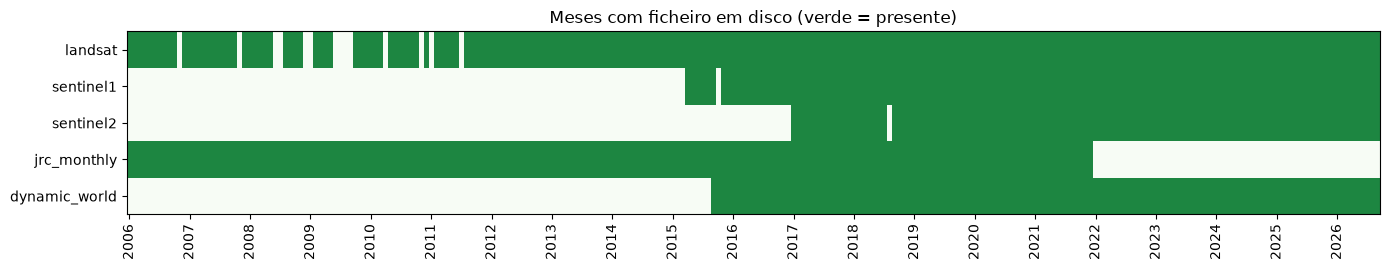

In [4]:
monthly = {"landsat": "landsat", "sentinel1": "sentinel1", "sentinel2": "sentinel2",
           "jrc_monthly": "jrc_monthly", "dynamic_world": "dynamic_world"}
months = pd.period_range(cfg["period"]["start"], config.period_end(cfg), freq="M").strftime("%Y-%m")
coverage = pd.DataFrame(
    {name: months.isin(series.monthly_inventory(config.path(cfg, key))["period"]) for name, key in monthly.items()},
    index=months)

fig, ax = plt.subplots(figsize=(14, 2.8))
ax.imshow(coverage.T.values, aspect="auto", cmap="Greens", vmin=0, vmax=1.3, interpolation="none")
ax.set_yticks(range(len(coverage.columns)), coverage.columns)
ticks = [i for i, m in enumerate(months) if m.endswith("-01")]
ax.set_xticks(ticks, [months[i][:4] for i in ticks], rotation=90)
ax.set_title("Meses com ficheiro em disco (verde = presente)")
plt.tight_layout()
coverage.groupby(coverage.index.str[:4]).sum().T

## 4. Manifesto de downloads

`absent` = a fonte não tinha nenhuma imagem para esse período (fica como em
falta, nunca é preenchido). `failed` = o pedido falhou; voltar a correr o
notebook do dataset. `downloaded` = descarregado com sucesso.

In [5]:
manifest_file = ROOT / cfg["paths"]["manifest"]
if manifest_file.exists():
    # um período pode ficar registado em várias execuções: manter o estado mais recente
    manifest = pd.read_csv(manifest_file).drop_duplicates(["dataset", "period", "bands"], keep="last")
    display(manifest.pivot_table(index="dataset", columns="status", values="period", aggfunc="count", fill_value=0))
    display(manifest[manifest["status"] == "failed"].tail(20))
else:
    print("ainda não há downloads registados")

status,absent,downloaded,failed
dataset,,,
aspect,0,1,0
chirps,0,21,0
dem,0,1,0
dynamicworld,2,133,0
era5land,0,105,0
flow_accumulation,0,1,0
glofas,0,21,21
hand,0,1,0
imerg,0,249,0


,timestamp_utc,dataset,source_id,period,status,n_images,file,bands,crs,resolution,note
1240,2026-10-08T16:32:53+00:00,glofas,cems-glofas-historical,2018,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
1241,2026-10-08T16:32:53+00:00,glofas,cems-glofas-historical,2019,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
1242,2026-10-08T16:32:54+00:00,glofas,cems-glofas-historical,2020,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
1243,2026-10-08T16:32:54+00:00,glofas,cems-glofas-historical,2021,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
1244,2026-10-08T16:32:55+00:00,glofas,cems-glofas-historical,2022,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
1245,2026-10-08T16:32:57+00:00,glofas,cems-glofas-historical,2023,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
1246,2026-10-08T16:32:57+00:00,glofas,cems-glofas-historical,2024,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
1247,2026-10-08T16:33:00+00:00,glofas,cems-glofas-historical,2025,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
1248,2026-10-08T16:33:01+00:00,glofas,cems-glofas-historical,2026,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
1249,2026-10-08T17:16:24+00:00,glofas,cems-glofas-historical,2006,failed,NaN,NaN,NaN,NaN,NaN,"HTTPError(""400 Client Error: Bad Request for u..."
